# Credit risk scoring: development demonstration

All costs are hypothetical units with orientation **C_FN:C_FP**. Class 1 is serious delinquency within two years, not legal default or realized loss. Thresholds minimize empirical validation cost, using the same development partition used for calibration selection. These costs are development results, not independent generalization estimates. No held-out test evaluation occurs.

A prediction is positive when p >= threshold. Exact cost ties choose the highest candidate threshold (fewer positive decisions). The all-negative reference uses a threshold just above one; preserve its full precision. Curve exports are sampled for display, but optimization considers every distinct score boundary.

## Shared workflow
Official CSV ? schema validation ? fixed stratified 70/15/15 split ? training-only preprocessing ? tuned LR/RF/XGBoost ? training-fold calibration ? validation-selected cost thresholds. This notebook only reads saved outputs.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RUN = ROOT / 'results/tables/05_cost_analysis'
if not (RUN / 'provenance.json').is_file():
    raise FileNotFoundError('Run python -m scripts.run_cost_analysis first.')
meta = json.loads((RUN / 'provenance.json').read_text())
assert meta['test_evaluated'] is False
print('Run:', RUN.name)
print(meta['interpretation'])
comparison = pd.read_csv(RUN / 'cost_comparison.csv')
selected = pd.read_csv(RUN / 'selected_thresholds.csv')
FIGURES = Path(meta['figures'])


Run: 05_cost_analysis
Validation-selected development results, not independent generalization or actual monetary losses


## Evaluation and calibration
ROC-AUC measures ranking; average precision emphasizes minority-class retrieval. Lower Brier and log loss indicate better probability accuracy. Reliability curves compare predicted risk with observed delinquency. All threshold confusion matrices in Member 4 use 0.5.

In [2]:
M4 = ROOT / 'results/tables/04_evaluation'
display(pd.read_csv(M4 / 'evaluation_summary.csv'))
display(pd.read_csv(M4 / 'paired_bootstrap_differences.csv'))
display(pd.read_csv(M4 / 'duplicate_sensitivity.csv'))

,model_name,calibration_method,selected_for_model,roc_auc,pr_auc_average_precision,brier_score,log_loss,expected_calibration_error,maximum_calibration_error,threshold,precision,recall,f1,tn,fp,fn,tp
0,logistic_tuned,uncalibrated,False,0.802057,0.313599,0.179387,0.582095,0.345482,0.460955,0.5,0.182329,0.668218,0.286488,16489,4507,499,1005
1,logistic_tuned,sigmoid,False,0.801677,0.312319,0.061895,0.242079,0.052634,0.234299,0.5,0.510638,0.015957,0.030948,20973,23,1480,24
2,logistic_tuned,isotonic,True,0.801977,0.312418,0.052922,0.199642,0.004175,0.012684,0.5,0.562667,0.140293,0.224588,20832,164,1293,211
3,random_forest_tuned,uncalibrated,False,0.869397,0.401304,0.048710,0.176171,0.005802,0.030049,0.5,0.588689,0.152261,0.241944,20836,160,1275,229
4,random_forest_tuned,sigmoid,False,0.869064,0.401420,0.050013,0.185757,0.020506,0.054025,0.5,0.583784,0.215426,0.314716,20765,231,1180,324
5,random_forest_tuned,isotonic,True,0.868971,0.399357,0.048695,0.175958,0.002914,0.012768,0.5,0.605911,0.163564,0.257592,20836,160,1258,246
6,xgboost_standard_tuned,uncalibrated,False,0.870081,0.404227,0.048523,0.175571,0.004187,0.016978,0.5,0.590517,0.182181,0.278455,20806,190,1230,274
7,xgboost_standard_tuned,sigmoid,False,0.870295,0.405021,0.050069,0.186487,0.021598,0.051365,0.5,0.584192,0.226064,0.325983,20754,242,1164,340
8,xgboost_standard_tuned,isotonic,True,0.870301,0.403007,0.048507,0.175321,0.002865,0.011668,0.5,0.586207,0.180851,0.276423,20804,192,1232,272


,base_model_a,base_model_b,candidate_a,candidate_b,metric,delta_model_b_minus_model_a,ci_lower,ci_upper,metric_direction,bootstrap_probability_model_b_better,confidence_level,n_resamples
0,logistic_tuned,random_forest_tuned,logistic_tuned__isotonic,random_forest_tuned__isotonic,roc_auc,0.066994,0.057682,0.076536,higher_is_better,1.000,0.95,1000
1,logistic_tuned,random_forest_tuned,logistic_tuned__isotonic,random_forest_tuned__isotonic,pr_auc_average_precision,0.086939,0.070633,0.103770,higher_is_better,1.000,0.95,1000
2,logistic_tuned,random_forest_tuned,logistic_tuned__isotonic,random_forest_tuned__isotonic,brier_score,-0.004227,-0.004953,-0.003517,lower_is_better,1.000,0.95,1000
3,logistic_tuned,random_forest_tuned,logistic_tuned__isotonic,random_forest_tuned__isotonic,log_loss,-0.023684,-0.027944,-0.020140,lower_is_better,1.000,0.95,1000
4,logistic_tuned,xgboost_standard_tuned,logistic_tuned__isotonic,xgboost_standard_tuned__isotonic,roc_auc,0.068324,0.059406,0.077788,higher_is_better,1.000,0.95,1000
5,logistic_tuned,xgboost_standard_tuned,logistic_tuned__isotonic,xgboost_standard_tuned__isotonic,pr_auc_average_precision,0.090589,0.074907,0.106952,higher_is_better,1.000,0.95,1000
6,logistic_tuned,xgboost_standard_tuned,logistic_tuned__isotonic,xgboost_standard_tuned__isotonic,brier_score,-0.004415,-0.005137,-0.003704,lower_is_better,1.000,0.95,1000
7,logistic_tuned,xgboost_standard_tuned,logistic_tuned__isotonic,xgboost_standard_tuned__isotonic,log_loss,-0.024320,-0.028577,-0.020860,lower_is_better,1.000,0.95,1000
8,random_forest_tuned,xgboost_standard_tuned,random_forest_tuned__isotonic,xgboost_standard_tuned__isotonic,roc_auc,0.001331,-0.000014,0.002617,higher_is_better,0.973,0.95,1000
9,random_forest_tuned,xgboost_standard_tuned,random_forest_tuned__isotonic,xgboost_standard_tuned__isotonic,pr_auc_average_precision,0.003650,-0.001145,0.008710,higher_is_better,0.924,0.95,1000


,base_model,candidate_name,subset,n_observations,n_positive,roc_auc,pr_auc_average_precision,brier_score,log_loss
0,logistic_tuned,logistic_tuned__isotonic,all_validation,22500,1504,0.801977,0.312418,0.052922,0.199642
1,logistic_tuned,logistic_tuned__isotonic,excluding_exact_train_duplicates,22384,1501,0.801590,0.314646,0.053054,0.200141
2,random_forest_tuned,random_forest_tuned__isotonic,all_validation,22500,1504,0.868971,0.399357,0.048695,0.175958
3,random_forest_tuned,random_forest_tuned__isotonic,excluding_exact_train_duplicates,22384,1501,0.868837,0.399249,0.048856,0.176438
4,xgboost_standard_tuned,xgboost_standard_tuned__isotonic,all_validation,22500,1504,0.870301,0.403007,0.048507,0.175321
5,xgboost_standard_tuned,xgboost_standard_tuned__isotonic,excluding_exact_train_duplicates,22384,1501,0.870183,0.402978,0.048664,0.175794


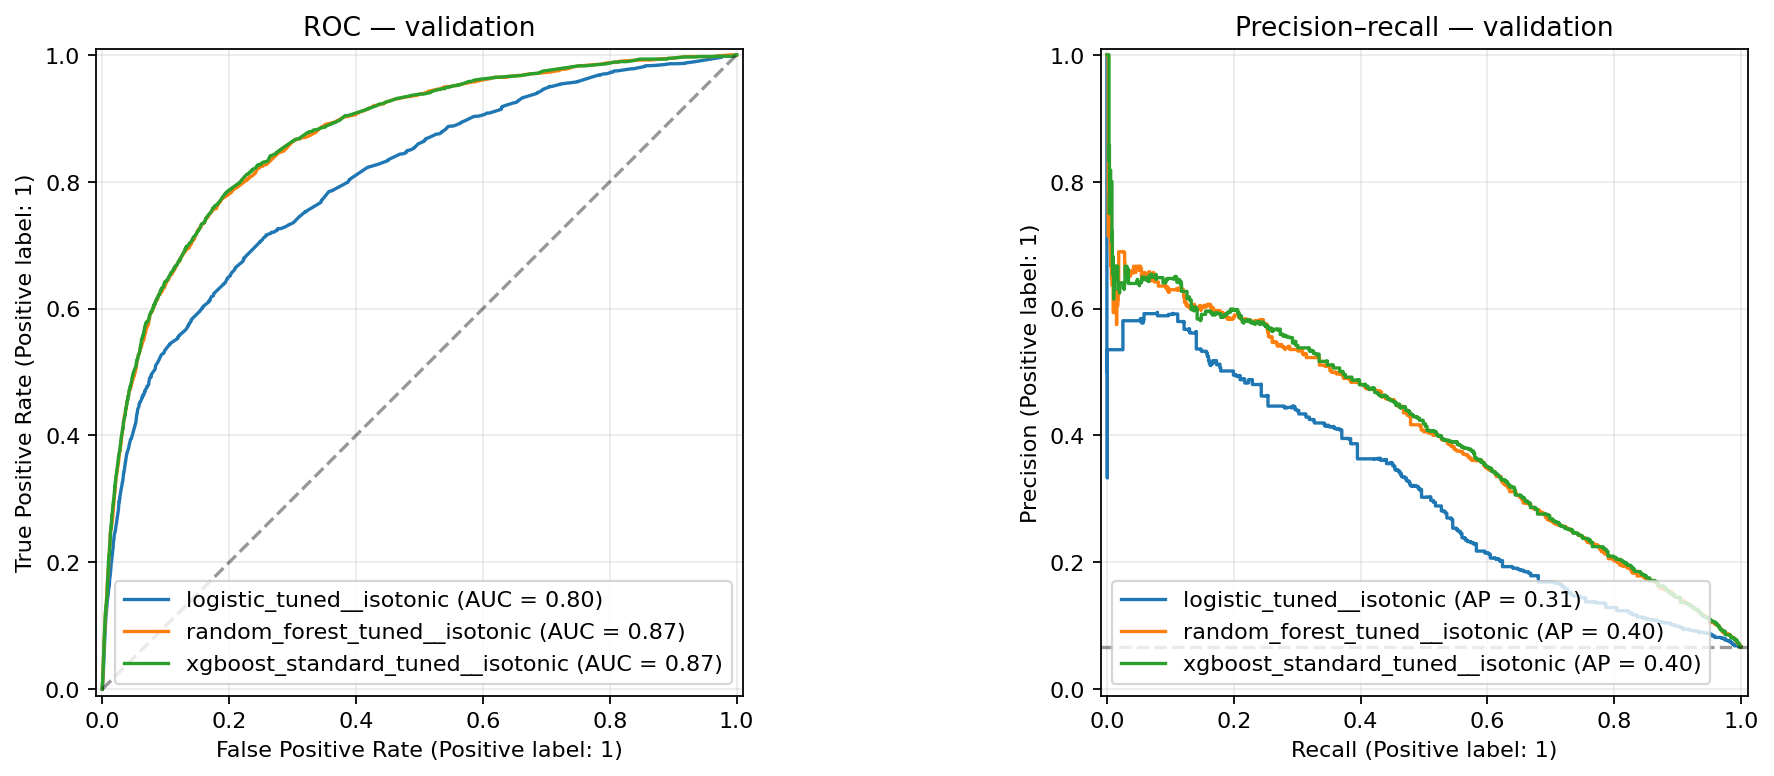

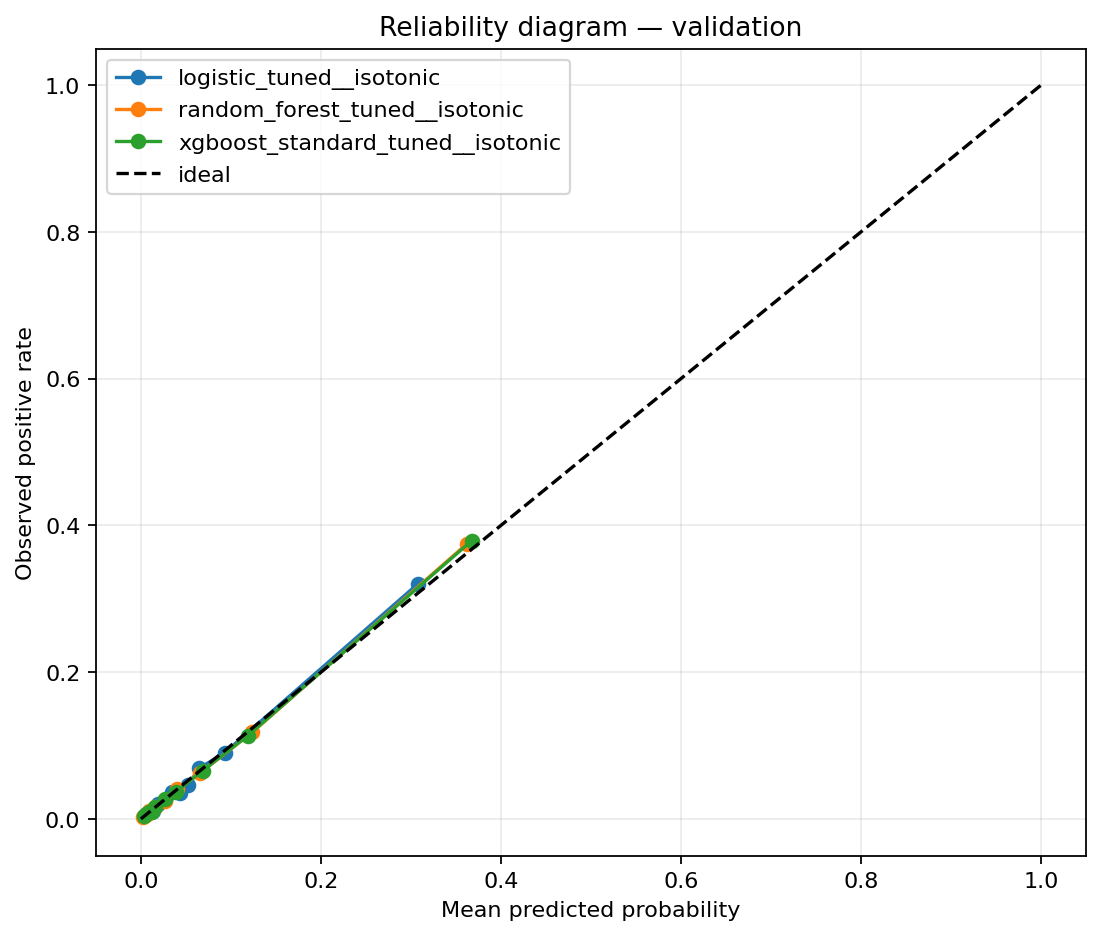

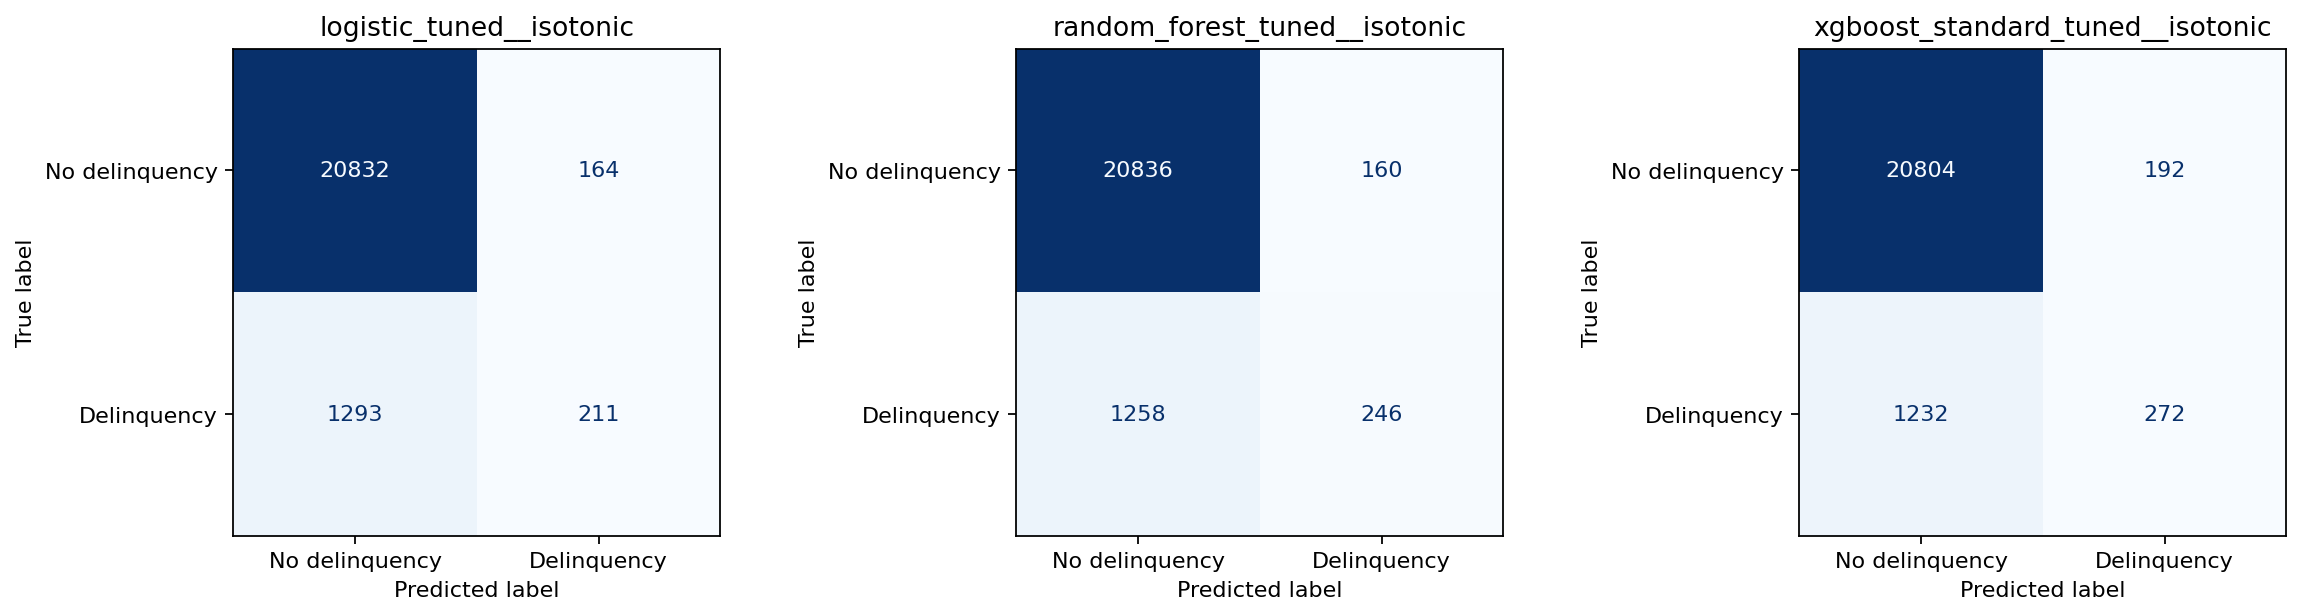

In [3]:
for name in ['roc_pr_validation.png','reliability_validation.png','confusion_matrices_validation.png']:
    display(Image(filename=str(ROOT / 'results/figures/04_evaluation' / name)))

## Hypothetical costs and validation thresholds

,model_name,cost_ratio,threshold,total_cost,cost_per_observation
0,logistic_tuned,1:1,0.892531,1452.0,0.064533
1,logistic_tuned,3:1,0.671058,3649.0,0.162178
2,logistic_tuned,5:1,0.623513,5341.0,0.237378
3,logistic_tuned,10:1,0.575649,9051.0,0.402267
4,logistic_tuned__isotonic,1:1,0.541008,1452.0,0.064533
5,logistic_tuned__isotonic,3:1,0.222451,3647.0,0.162089
6,logistic_tuned__isotonic,5:1,0.175847,5356.0,0.238044
7,logistic_tuned__isotonic,10:1,0.108924,9062.0,0.402756
8,random_forest_tuned,1:1,0.457095,1399.0,0.062178
9,random_forest_tuned,3:1,0.256561,3283.0,0.145911


,base_model,c_fn,c_fp,isotonic,uncalibrated,isotonic_minus_uncalibrated_cost
0,logistic_tuned,1,1,1452.0,1452.0,0.0
1,logistic_tuned,3,1,3647.0,3649.0,-2.0
2,logistic_tuned,5,1,5356.0,5341.0,15.0
3,logistic_tuned,10,1,9062.0,9051.0,11.0
4,random_forest_tuned,1,1,1399.0,1399.0,0.0
5,random_forest_tuned,3,1,3279.0,3283.0,-4.0
6,random_forest_tuned,5,1,4655.0,4657.0,-2.0
7,random_forest_tuned,10,1,7291.0,7306.0,-15.0
8,xgboost_standard_tuned,1,1,1402.0,1396.0,6.0
9,xgboost_standard_tuned,3,1,3271.0,3268.0,3.0


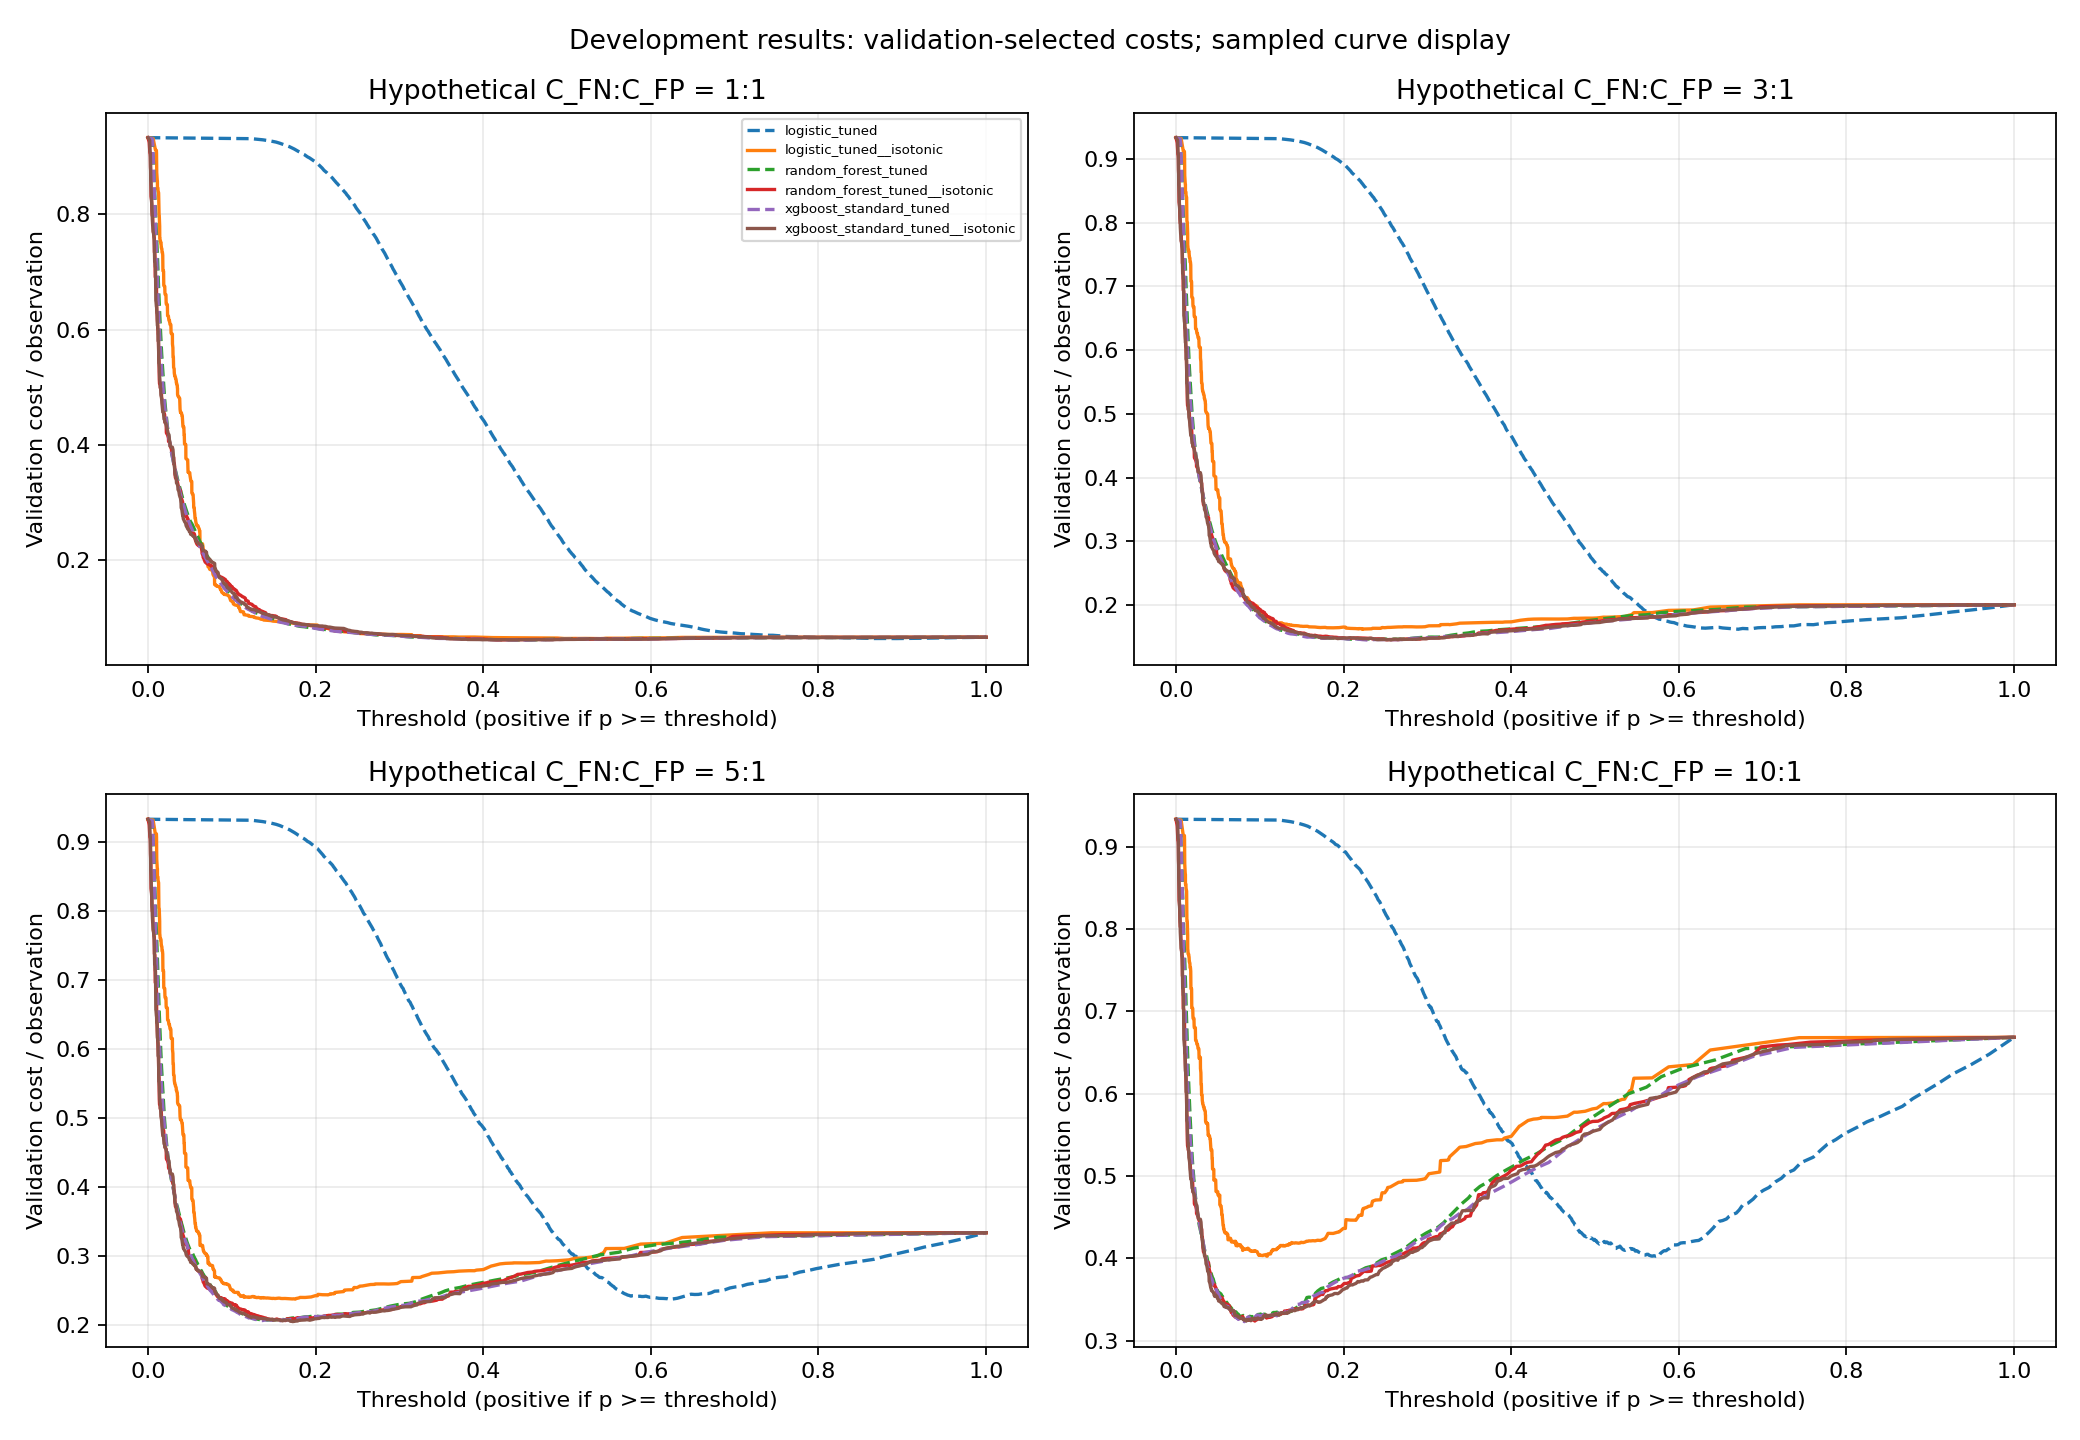

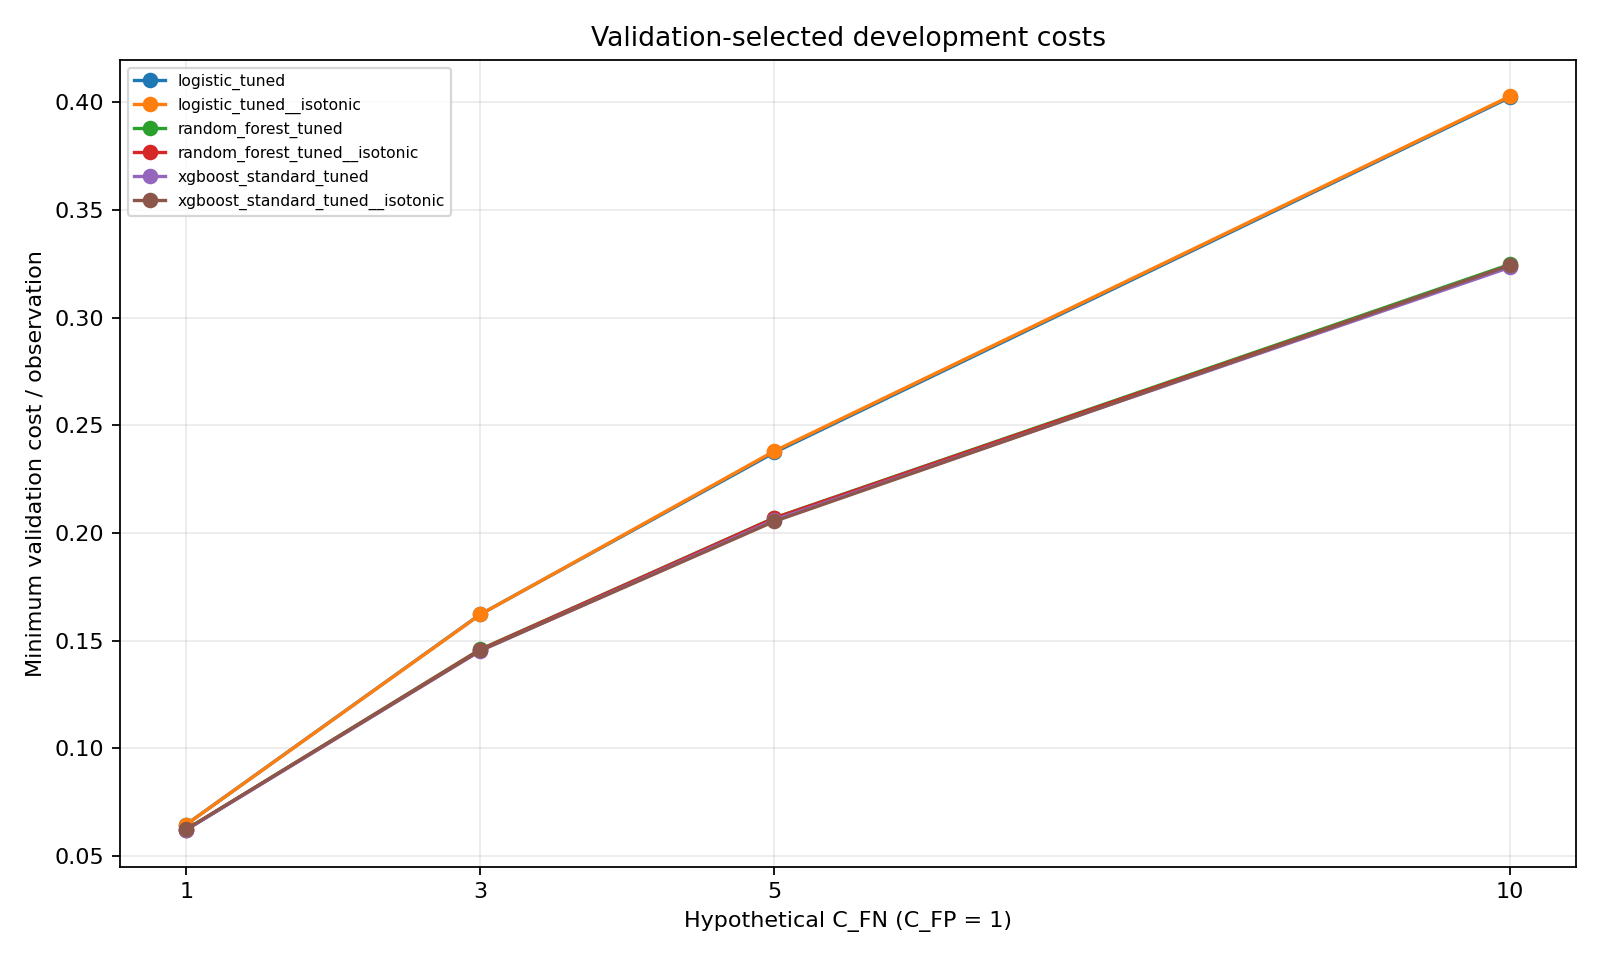

In [4]:
display(selected[['model_name','cost_ratio','threshold','total_cost','cost_per_observation']])
display(pd.read_csv(RUN / 'calibration_cost_comparison.csv'))
for name in ['threshold_cost_sensitivity.png','cost_ratio_sensitivity.png']:
    display(Image(filename=str(FIGURES / name)))

## SHAP: original uncalibrated XGBoost only
These explanations describe `xgboost_standard_tuned`, **not** its isotonic-calibrated ensemble. Contributions are on the original XGBoost margin/log-odds scale, not additive probability changes. The local export shows only the top 10 of 12 contributions and cannot reconstruct the complete prediction. Feature contributions are not causal effects.

,feature,mean_absolute_shap,mean_shap
0,RevolvingUtilizationOfUnsecuredLines,0.552597,0.103200
1,NumberOfTime30-59DaysPastDueNotWorse,0.268000,0.023374
2,age,0.205021,-0.004151
3,NumberOfTimes90DaysLate,0.198443,0.011886
4,NumberOfTime60-89DaysPastDueNotWorse,0.157600,-0.036150
5,NumberOfOpenCreditLinesAndLoans,0.123718,0.015145
6,DebtRatio,0.087690,-0.004514
7,MonthlyIncome,0.080737,0.010153
8,NumberRealEstateLoansOrLines,0.065780,0.022395
9,missingindicator_MonthlyIncome,0.031261,0.007673


,case_type,sample_id,y_true,y_pred_proba,model_name,split,predicted_label
0,highest_risk_positive,21879,1,0.851815,xgboost_standard_tuned,validation,1
1,false_positive,106886,0,0.818104,xgboost_standard_tuned,validation,1
2,false_negative,108343,1,0.498307,xgboost_standard_tuned,validation,0


,case_type,sample_id,y_true,predicted_probability,rank,feature,transformed_feature_value,shap_value,absolute_shap,base_value
0,highest_risk_positive,21879,1,0.851815,1,NumberOfTimes90DaysLate,9.000000,1.803519,1.803519,-3.620197
1,highest_risk_positive,21879,1,0.851815,2,RevolvingUtilizationOfUnsecuredLines,1.459344,1.367463,1.367463,-3.620197
2,highest_risk_positive,21879,1,0.851815,3,NumberOfTime60-89DaysPastDueNotWorse,7.000000,1.020296,1.020296,-3.620197
3,highest_risk_positive,21879,1,0.851815,4,NumberOfTime30-59DaysPastDueNotWorse,3.000000,0.896941,0.896941,-3.620197
4,highest_risk_positive,21879,1,0.851815,5,NumberOfOpenCreditLinesAndLoans,18.000000,0.178930,0.178930,-3.620197
5,highest_risk_positive,21879,1,0.851815,6,MonthlyIncome,5382.000000,0.044134,0.044134,-3.620197
6,highest_risk_positive,21879,1,0.851815,7,missingindicator_MonthlyIncome,1.000000,-0.043793,0.043793,-3.620197
7,highest_risk_positive,21879,1,0.851815,8,age,54.000000,0.037725,0.037725,-3.620197
8,highest_risk_positive,21879,1,0.851815,9,DebtRatio,1718.000000,0.036692,0.036692,-3.620197
9,highest_risk_positive,21879,1,0.851815,10,NumberRealEstateLoansOrLines,0.000000,0.025566,0.025566,-3.620197


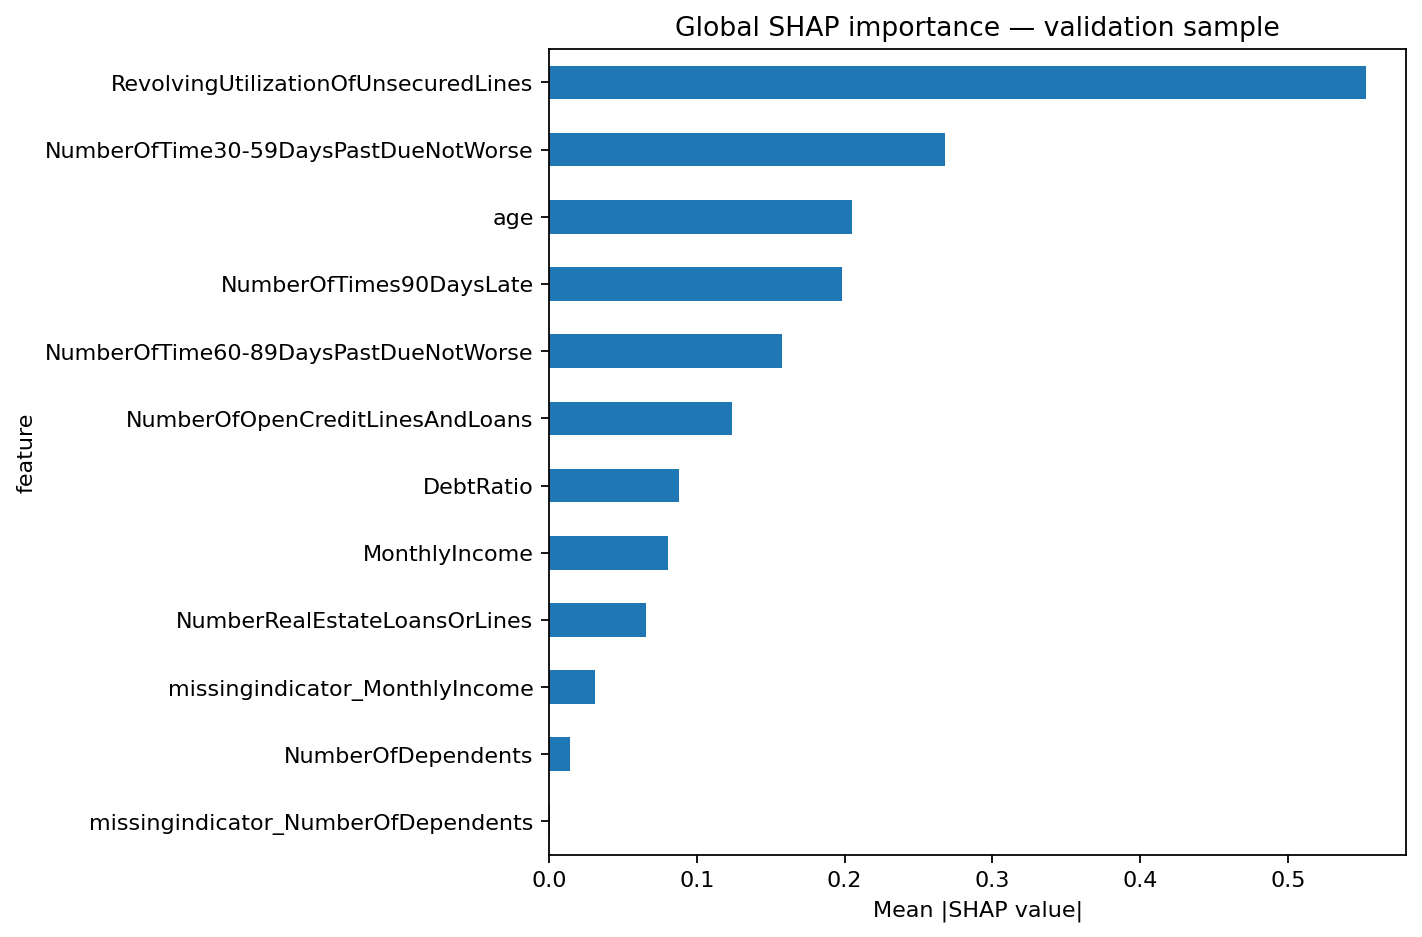

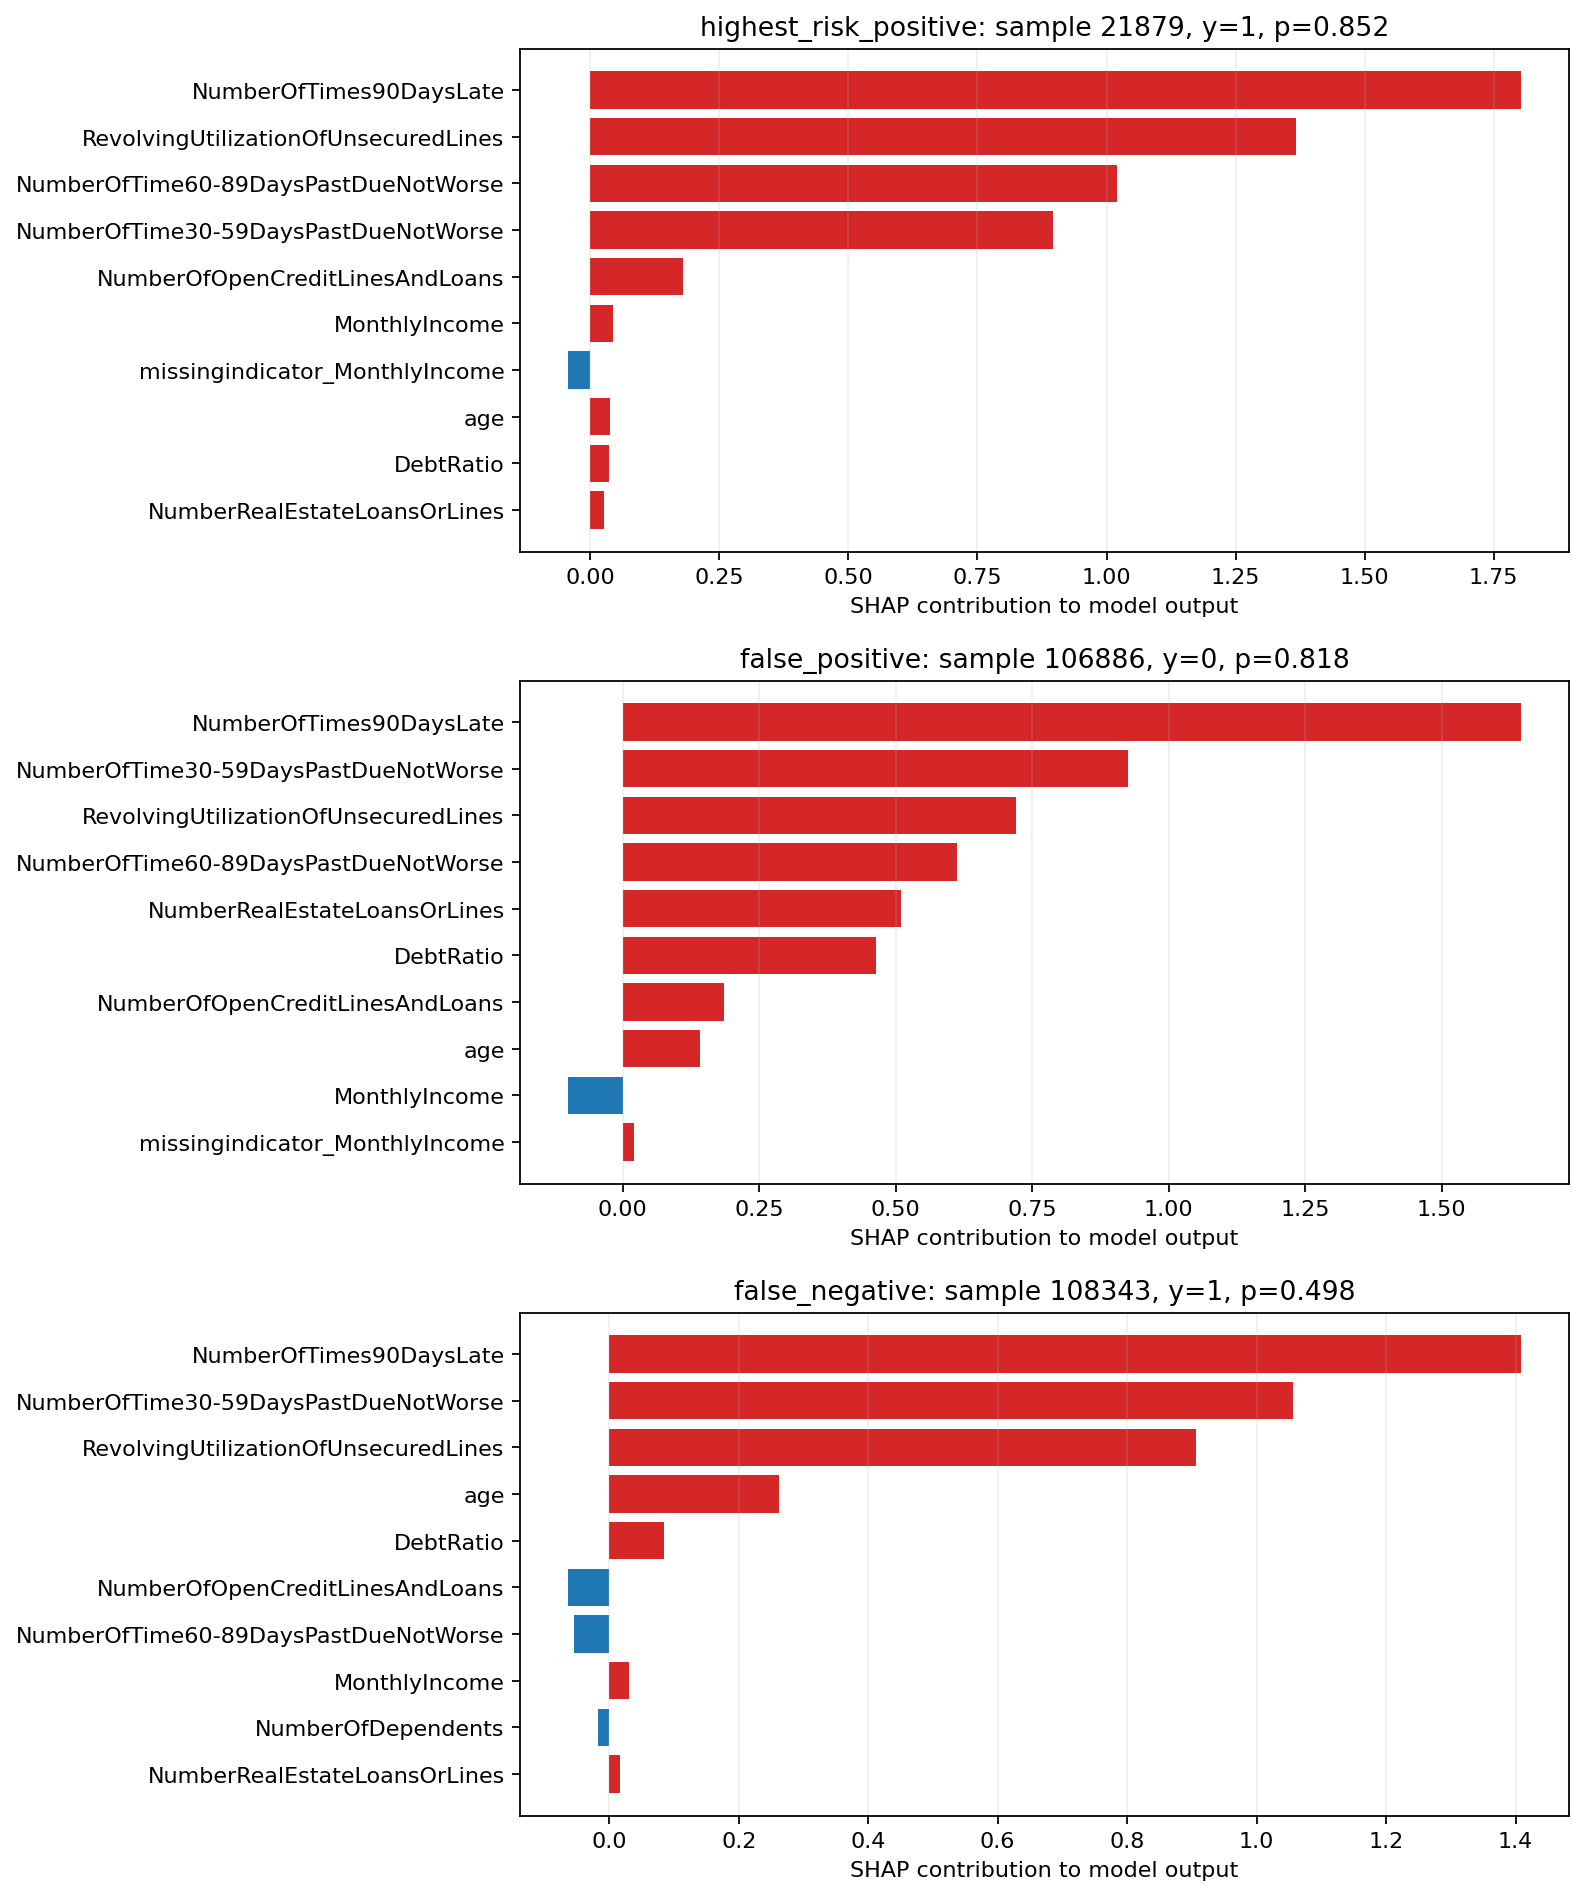

In [5]:
display(pd.read_csv(M4 / 'shap_global_importance.csv'))
display(pd.read_csv(M4 / 'shap_representative_cases.csv'))
display(pd.read_csv(M4 / 'shap_local_explanations.csv'))
for name in ['shap_global_importance.png','shap_local_cases.png']:
    display(Image(filename=str(ROOT / 'results/figures/04_evaluation' / name)))

## Decision boundary and remaining QA
This is a research demonstration, not a lending decision service. Preserve the test partition until model/calibration/threshold choices are locked and final evaluation is explicitly approved. Small RF/XGB differences require the uncertainty qualifications above. Review visuals and documentation before submission. Notebook 01?04 changes remain separate from this work.

In [6]:
print('Analysis:',meta['analysis_name'])
print('Fingerprint:',meta['split_fingerprint'])
print('Test evaluated:',meta['test_evaluated'])
display(pd.DataFrame(meta['inputs']).T)

Analysis: 05_cost_analysis
Fingerprint: 749ec0258bc5cf33375b61742d626c109dbda73d05428267d7575224a5b21dd7
Test evaluated: False


,path,sha256,sha256_at_generation
logistic_tuned,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,d9b42a860fb9eebe30a0cd4fcb941cdbcf078bdcf0a47f...,NaN
logistic_tuned__isotonic,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,ff3c08a35852edfa8d5d96fa386dd3bd06f850be5c9d2d...,NaN
random_forest_tuned,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,3afed82e60186962ce663271825710f6a19d44bb4a1d91...,NaN
random_forest_tuned__isotonic,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,0659cda1a10e3588adc454741b98a52a7a443c16bf21e0...,NaN
xgboost_standard_tuned,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,57b04a2bd603eb2ba80c958002f6b73b0127af286afecd...,NaN
xgboost_standard_tuned__isotonic,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,a08c131338ee85f37b2493d4d76315f0c2397557df9fe3...,NaN
split_manifest,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,31c2813385ba66e836f41233abeeafca1441c9d782afe2...,NaN
member4_configuration,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,e110c1a304a956e0deafd58fac60fbc66effe23f0c30bf...,aab454b49f34f08f9c0397005261f6a784a9500da40973...
cost_source,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,2b2aaaf012478e18a0128f7d8394230aa79d2d8ccb0b3c...,NaN
runner_source,C:\Users\ASUS\OneDrive\Documents\GitHub\CO3135...,7761405fc200a1ca1b40a8c89997fda523c5345751b167...,3b0720b5bea0a8497c0eead3e531f0f7b6b256d52fca59...
